In [39]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Embedding, Dropout, LayerNormalization, MultiHeadAttention, Reshape
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [40]:
import warnings
warnings.filterwarnings("ignore")

In [41]:
df = pd.read_csv('news.csv')
df.head()

,source,title,text,publication_date,rubric,subrubric,tags
0,lenta.ru,Синий богатырь,В 1930-е годы Советский Союз охватила лихорадк...,2020-08-30T00:01:00+03:00,Экономика,Госэкономика,NaN
1,lenta.ru,Загитова согласилась вести «Ледниковый период»,Олимпийская чемпионка по фигурному катанию Ал...,2020-08-31T20:04:00+03:00,Спорт,Зимние виды,NaN
2,lenta.ru,Объяснена опасность однообразного питания,Российский врач-диетолог Римма Мойсенко объясн...,2020-08-31T20:07:00+03:00,Из жизни,Еда,NaN
3,lenta.ru,«Предохраняться? А зачем?»,В 2019 году телеканал «Ю» запустил адаптацию з...,2020-08-30T00:04:00+03:00,Интернет и СМИ,ТВ и радио,NaN
4,lenta.ru,Ефремов систематически употреблял наркотики,Актер Михаил Ефремов систематически употребл...,2020-08-31T18:27:00+03:00,Культура,Кино,NaN


In [42]:
text = ''
for s in df['text'].head(700).values:
    text += s
text

'В 1930-е годы Советский Союз охватила лихорадка — в десятилетие бурной индустриализации повсюду гремели сообщения о новых трудовых подвигах простого народа ради построения коммунизма и светлого будущего. Первым из них стал шахтер из Донбасса  Алексей Стаханов . 85 лет назад он установил рекорд по добыче угля за смену и на следующее утро проснулся знаменитым на весь мир. Его одаривали квартирами и машинами, возили по Союзу, он стал любимцем Сталина, однако в итоге не выдержал славы и спился. Фамилия Стаханова, которая дала название движению трудовиков, превратилась в нарицательную и продолжила существовать отдельно от него. Живая витрина коммунизма — в материале  «Ленты.ру» . История легенды советского труда началась на шахте «Центральная-Ирмино» в Донбассе. К 1935 году советские власти запустили вторую пятилетку и активно проводили политику ускоренной индустриализации, пытаясь по заветам Владимира Ленина догнать и перегнать развитые капиталистические страны, от которых безнадежно отст

In [43]:
import spacy

nlp = spacy.load("ru_core_news_sm")

doc = nlp(text)
filtered_words = [token.text for token in doc if not token.is_stop]
text = " ".join(filtered_words)
text

'1930-е годы Советский Союз охватила лихорадка — десятилетие бурной индустриализации повсюду гремели сообщения новых трудовых подвигах простого народа построения коммунизма светлого будущего . Первым шахтер Донбасса   Алексей Стаханов . 85 лет установил рекорд добыче угля смену следующее утро проснулся знаменитым мир . одаривали квартирами машинами , возили Союзу , любимцем Сталина , итоге выдержал славы спился . Фамилия Стаханова , дала название движению трудовиков , превратилась нарицательную продолжила существовать отдельно . Живая витрина коммунизма — материале   « Ленты.ру » . История легенды советского труда началась шахте « Центральная - Ирмино » Донбассе . 1935 году советские власти запустили вторую пятилетку активно проводили политику ускоренной индустриализации , пытаясь заветам Владимира Ленина догнать перегнать развитые капиталистические страны , безнадежно отстали экономическом плане распада Российской империи . препятствием пути низкая производительность труда советских р

In [44]:
import re

text = re.sub(r'[^а-яА-ЯёЁ .]', '', text)

text = re.sub(r'\s+', ' ', text).strip()
text = text.lower()
text

'е годы советский союз охватила лихорадка десятилетие бурной индустриализации повсюду гремели сообщения новых трудовых подвигах простого народа построения коммунизма светлого будущего . первым шахтер донбасса алексей стаханов . лет установил рекорд добыче угля смену следующее утро проснулся знаменитым мир . одаривали квартирами машинами возили союзу любимцем сталина итоге выдержал славы спился . фамилия стаханова дала название движению трудовиков превратилась нарицательную продолжила существовать отдельно . живая витрина коммунизма материале ленты.ру . история легенды советского труда началась шахте центральная ирмино донбассе . году советские власти запустили вторую пятилетку активно проводили политику ускоренной индустриализации пытаясь заветам владимира ленина догнать перегнать развитые капиталистические страны безнадежно отстали экономическом плане распада российской империи . препятствием пути низкая производительность труда советских рабочих . угольной промышленности повышению ме

# BOW

In [ ]:
sentences = [s.strip() for s in text.split('.') if len(s.strip()) > 0]

vectorizer = CountVectorizer(max_features=5000)
X_bow = vectorizer.fit_transform(sentences)
vocab_size = len(vectorizer.vocabulary_)

In [ ]:
word_index = vectorizer.vocabulary_
sequences = []
for sentence in sentences:
    sequence = [word_index[word] for word in sentence.split() if word in word_index]
    sequences.append(sequence)

X = []
y = []
for seq in sequences:
    for i in range(1, len(seq)):
        X.append(seq[:i])
        y.append(seq[i])

max_len = max(len(x) for x in X)
X_padded = np.zeros((len(X), max_len), dtype=np.int32)
for i, seq in enumerate(X):
    X_padded[i, -len(seq):] = seq

y_onehot = np.zeros((len(y), vocab_size))
y_onehot[np.arange(len(y)), y] = 1

X_train, X_test, y_train, y_test = train_test_split(
    X_padded, y_onehot, test_size=0.2, random_state=42
)

In [46]:
def transformer_block(x, head_size, num_heads, ff_dim, dropout=0.05):
    # Multi-head self-attention
    attn_output = MultiHeadAttention(
        num_heads=num_heads, 
        key_dim=head_size
    )(x, x)
    attn_output = Dropout(dropout)(attn_output)
    x = LayerNormalization(epsilon=1e-6)(x + attn_output)
    
    # Feed-forward network
    ff_output = Dense(ff_dim, activation="relu")(x)
    ff_output = Dense(x.shape[-1])(ff_output)
    ff_output = Dropout(dropout)(ff_output)
    return LayerNormalization(epsilon=1e-6)(x + ff_output)

def build_bow_transformer(vocab_size, max_len):
    inputs = Input(shape=(max_len,)) 
    
    # Embedding + Positional Encoding
    x = Embedding(input_dim=vocab_size, output_dim=64)(inputs)
    
    # Transformer
    x = transformer_block(x, head_size=64, num_heads=2, ff_dim=128)
    x = transformer_block(x, head_size=64, num_heads=2, ff_dim=128)
    
    # Global Average Pooling
    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    
    # Выходной слой
    outputs = Dense(vocab_size, activation='softmax')(x)
    
    model = Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [49]:
bow_model = build_bow_transformer(vocab_size, max_len)

bow_history = bow_model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_test, y_test)
)

Epoch 1/10
583/583 ━━━━━━━━━━━━━━━━━━━━ 51s 77ms/step - accuracy: 0.0076 - loss: 8.2863 - val_accuracy: 0.0097 - val_loss: 8.0388
Epoch 2/10
583/583 ━━━━━━━━━━━━━━━━━━━━ 46s 79ms/step - accuracy: 0.0110 - loss: 7.8618 - val_accuracy: 0.0159 - val_loss: 7.8930
Epoch 3/10
583/583 ━━━━━━━━━━━━━━━━━━━━ 47s 80ms/step - accuracy: 0.0183 - loss: 7.5661 - val_accuracy: 0.0223 - val_loss: 7.7188
Epoch 4/10
583/583 ━━━━━━━━━━━━━━━━━━━━ 48s 82ms/step - accuracy: 0.0333 - loss: 7.2149 - val_accuracy: 0.0356 - val_loss: 7.5796
Epoch 5/10
583/583 ━━━━━━━━━━━━━━━━━━━━ 50s 86ms/step - accuracy: 0.0543 - loss: 6.7339 - val_accuracy: 0.0480 - val_loss: 7.5293
Epoch 6/10
583/583 ━━━━━━━━━━━━━━━━━━━━ 44s 75ms/step - accuracy: 0.0816 - loss: 6.2245 - val_accuracy: 0.0634 - val_loss: 7.6131
Epoch 7/10
583/583 ━━━━━━━━━━━━━━━━━━━━ 48s 82ms/step - accuracy: 0.1114 - loss: 5.7045 - val_accuracy: 0.0695 - val_loss: 7.7090
Epoch 8/10
583/583 ━━━━━━━━━━━━━━━━━━━━ 45s 77ms/step - accuracy: 0.1400 - loss: 5.2199 - 

In [50]:
def generate_text(model, vectorizer, seed_text, num_words=10):
    word_index = vectorizer.vocabulary_
    index_word = {v: k for k, v in word_index.items()}
    
    current_sequence = [word_index[word] for word in seed_text.split() if word in word_index]
    generated_words = seed_text.split()
    
    for _ in range(num_words):
        padded_sequence = np.zeros((1, max_len), dtype=np.int32)
        seq_to_pad = current_sequence[-max_len:] 
        padded_sequence[0, -len(seq_to_pad):] = seq_to_pad
        
        pred = model.predict(padded_sequence, verbose=0)
        next_word_idx = np.argmax(pred[0])
        next_word = index_word.get(next_word_idx, '')
        
        if not next_word:
            break
            
        generated_words.append(next_word)
        current_sequence.append(next_word_idx)
    
    return ' '.join(generated_words)

In [51]:
print(generate_text(bow_model, vectorizer, "время"))

время актера вылетел встречную полосу полосу столкнулся фургоном захаров скончался скончался


# N-gramms

In [52]:
n_gram_length = 6
max_sequence_length = 100

tokenizer = Tokenizer(num_words=5000)  
tokenizer.fit_on_texts([text])
total_words = tokenizer.num_words + 1 

input_sequences = []
for line in text.split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(n_gram_length, len(token_list)):
        n_gram_sequence = token_list[i-n_gram_length:i+1]
        input_sequences.append(n_gram_sequence)

input_sequences = np.array(pad_sequences(input_sequences, maxlen=n_gram_length+1, padding='post'))
X_ngram, y_ngram = input_sequences[:, :-1], input_sequences[:, -1]  

X_train_ngram, X_test_ngram, y_train_ngram, y_test_ngram = train_test_split(
    X_ngram, y_ngram, test_size=0.2, random_state=42
)

In [53]:
def build_ngram_transformer(vocab_size, max_len, embed_dim=128, num_heads=4, ff_dim=256):
    inputs = Input(shape=(max_len,))
    
    # Embedding с позиционным кодированием
    x = Embedding(vocab_size, embed_dim, input_length=max_len)(inputs)
    
    # Позиционное кодирование
    positions = tf.range(start=0, limit=max_len, delta=1)
    positions = Embedding(max_len, embed_dim)(positions)
    x = x + positions
    
    # Transformer Block
    attn_output = MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim//num_heads)(x, x)
    x = LayerNormalization(epsilon=1e-6)(x + attn_output)
    
    ffn = Dense(ff_dim, activation="relu")(x)
    ffn = Dense(embed_dim)(ffn)
    x = LayerNormalization(epsilon=1e-6)(x + ffn)
    
    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = Dropout(0.2)(x)
    outputs = Dense(vocab_size, activation='softmax')(x)
    
    model = Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [57]:
from tensorflow.keras.callbacks import EarlyStopping

In [58]:
ngram_transformer = build_ngram_transformer(
    vocab_size=total_words,
    max_len=n_gram_length, 
    embed_dim=128,
    num_heads=4
)

early_stopping = EarlyStopping(
        monitor='val_loss',    # Мониторим validation loss
        patience=2,           # Ждем 2 эпохи без улучшения
)

ngram_history = ngram_transformer.fit(
    X_train_ngram,
    y_train_ngram,
    batch_size=64,
    epochs=10,
    validation_data=(X_test_ngram, y_test_ngram), 
    callbacks=[early_stopping]
)

Epoch 1/10
694/694 ━━━━━━━━━━━━━━━━━━━━ 35s 46ms/step - accuracy: 0.0091 - loss: 8.2127 - val_accuracy: 0.0340 - val_loss: 7.7204
Epoch 2/10
694/694 ━━━━━━━━━━━━━━━━━━━━ 32s 47ms/step - accuracy: 0.0579 - loss: 7.0208 - val_accuracy: 0.0886 - val_loss: 7.2017
Epoch 3/10
694/694 ━━━━━━━━━━━━━━━━━━━━ 39s 56ms/step - accuracy: 0.1717 - loss: 5.4431 - val_accuracy: 0.1313 - val_loss: 7.1785
Epoch 4/10
694/694 ━━━━━━━━━━━━━━━━━━━━ 34s 49ms/step - accuracy: 0.2974 - loss: 3.9907 - val_accuracy: 0.1426 - val_loss: 7.5447
Epoch 5/10
694/694 ━━━━━━━━━━━━━━━━━━━━ 32s 46ms/step - accuracy: 0.4334 - loss: 2.8733 - val_accuracy: 0.1508 - val_loss: 8.0884


In [61]:
def generate_text(model, tokenizer, seed_text, next_words=10, n_gram_length=6, temperature=1.0):
    generated_text = seed_text
    token_sequence = tokenizer.texts_to_sequences([seed_text])[0]
    
    for _ in range(next_words):
        # Берем последние n_gram_length токенов
        input_sequence = token_sequence[-n_gram_length:]
        padded_sequence = pad_sequences([input_sequence], maxlen=n_gram_length, padding='pre')
        
        # Получаем предсказания модели
        predictions = model.predict(padded_sequence, verbose=0)[0]
        
        # Применяем temperature для регулирования случайности
        if temperature != 1.0:
            predictions = np.log(predictions) / temperature
            exp_preds = np.exp(predictions)
            predictions = exp_preds / np.sum(exp_preds)
        
        # Выбираем следующее слово
        next_index = np.random.choice(len(predictions), p=predictions)
        next_word = tokenizer.index_word.get(next_index, '')
        
        # Обновляем последовательность
        generated_text += " " + next_word
        token_sequence.append(next_index)
    
    return generated_text

In [62]:
seed_text = "время"
print(generate_text(ngram_transformer, tokenizer, seed_text))

время случай героини оказалась медицинскую сняла пост дону белоруссии действиями силовиков


In [63]:
def plot_history(history, title):
    plt.figure(figsize=(12, 4))
    plt.suptitle(title)
    
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Accuracy')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss')
    plt.legend()
    
    plt.show()

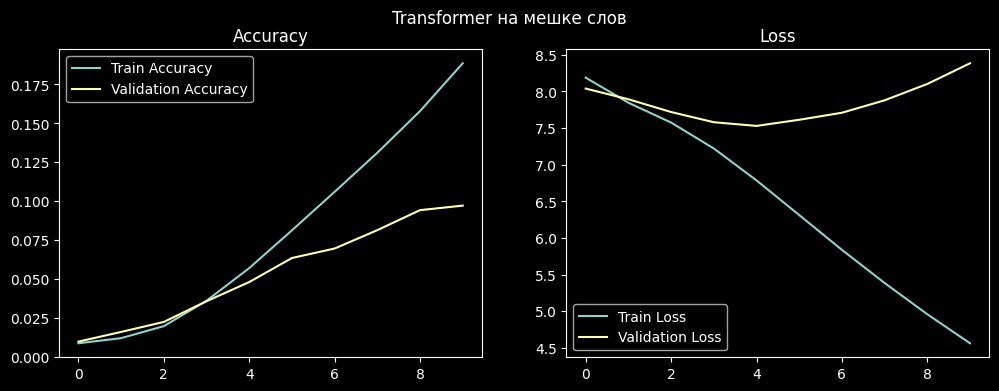

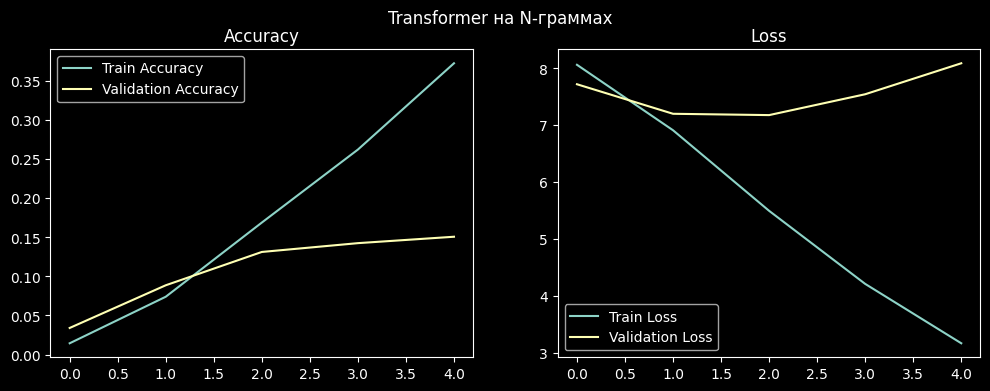

In [64]:
plot_history(bow_history, 'Transformer на мешке слов')
plot_history(ngram_history, 'Transformer на N-граммах')